In [1]:
import os
from uuid import uuid4

import mlflow
from dotenv import load_dotenv
from IPython.display import Image, display
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode
from tavily import TavilyClient

In [2]:
mlflow.langchain.autolog()

tracking_uri = "http://127.0.0.1:5000"
mlflow.set_tracking_uri(tracking_uri)

In [3]:
experiment = mlflow.set_experiment("LangGraph Observability")

experiment

<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1794420313771, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1794420313771, lifecycle_stage='active', name='LangGraph Observability', tags={}, trace_location=None, workspace='default'>

In [4]:
@mlflow.trace
def add(a: int, b: int) -> int:
    """Add 2 integers and return as integer"""
    return a + b

In [5]:
add(1, 2)

3

In [6]:
load_dotenv()

True

In [ ]:
model = "gpt-5.6-sol"

llm = ChatOpenAI(
    model=model,
    temperature=0.0,
    max_tokens=500,
    timeout=50,
    reasoning_effort="low",
    max_retries=2,
)

In [8]:
@tool
def web_search(question: str) -> dict:
    """
    Return top search results for a given search query
    """
    tavily_client = TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))
    response = tavily_client.search(question)
    return response

In [9]:
class State(MessagesState):
    question: str
    answer: str

In [10]:
llm_with_tools = llm.bind_tools([web_search])

In [11]:
def entry_point(state: State):
    question = state["question"]
    system_message = SystemMessage(
        "You conduct web search to respond to user's questions"
    )
    human_message = HumanMessage(question)
    messages = [system_message, human_message]
    return {"messages": messages}

In [12]:
def agent(state: State):
    messages = state["messages"]
    ai_message = llm_with_tools.invoke(messages)
    return {"messages": ai_message, "answer": ai_message.content}

In [13]:
def router(state: MessagesState):
    last_message = state["messages"][-1]
    if last_message.tool_calls:
        return "tools"

    return END

In [14]:
workflow = StateGraph(State)
workflow.add_node("entry_point", entry_point)
workflow.add_node("agent", agent)
workflow.add_node("tools", ToolNode([web_search]))

workflow.add_edge(START, "entry_point")
workflow.add_edge("entry_point", "agent")
workflow.add_conditional_edges(source="agent", path=router, path_map=["tools", END])
workflow.add_edge("tools", "agent")

In [15]:
checkpointer = InMemorySaver()

graph = workflow.compile(interrupt_before=["tools"], checkpointer=checkpointer)

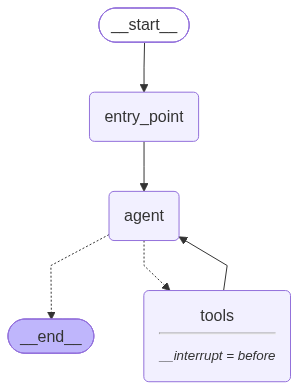

In [16]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [17]:
input_question = {"question": "what's the capital of Brazil?"}
config = {"configurable": {"thread_id": str(uuid4())}}

In [18]:
for chunk in graph.stream(input=input_question, config=config, stream_mode="values"):
    if not chunk["messages"]:
        continue
    chunk["messages"][-1].pretty_print()

================================ Human Message =================================

what's the capital of Brazil?
================================== Ai Message ==================================

[{'type': 'text', 'text': 'The capital of Brazil is **Brasília**.', 'annotations': [], 'id': 'msg_03d140ec696e00c4006af4b3ab944c87d2b8bc265f1c39f8ad', 'phase': 'final_answer'}]


Trace(trace_id='tr-807f76d2a9a58f2ae085ed3ac10ff4e9')

In [19]:
state = graph.get_state(config=config)

In [20]:
state.next

()

In [21]:
for chunk in graph.stream(input=None, config=config, stream_mode="values"):
    if not chunk["messages"]:
        continue
    chunk["messages"][-1].pretty_print()

================================== Ai Message ==================================

[{'type': 'text', 'text': 'The capital of Brazil is **Brasília**.', 'annotations': [], 'id': 'msg_03d140ec696e00c4006af4b3ab944c87d2b8bc265f1c39f8ad', 'phase': 'final_answer'}]
